# Chart data extraction benchmark — 12 real figures, rebuilt with exact ground truth

**Figures:** 6 line / scatter plots (FTIR, pore size, methane, dosage, N2 isotherm, kinetics), 4 bar charts (pH, soil concentration, plant-quality dual-axis bars, 18-category impact chart) and 2 3D pie charts. Bar data: x = category index, y = bar height, yerr = error bar. Pie data: x = slice index, y = percentage (the printed labels; the classical digitizer measures the slice angles as a check).

**Adding new figures:** describe them in `chartbench/figures.py`, then run the cells up to and including **3a** (classical digitizer). Figures that already have reference data / rebuilt images / cached answers are not redone.

**What this notebook does, in order**

| Stage | What happens | Output |
|---|---|---|
| 0 | All settings in one place (next cell) | parameter table |
| 1 | The classical digitizer reads every **original** figure → first-version (v1) data | `outputs/reference_v1/` + overlays |
| 2 | Each figure is **rebuilt** from the v1 data (same size, axes, fonts, colours). The v1 data is the rebuilt image's **exact ground truth** | `outputs/rebuilt_plots/`, `outputs/ground_truth/` |
| 3 | Every model reads the original **and** rebuilt images, one cell per model. Under each cell: **one table per figure** (rows of 3): truth vs. model value for every point | `outputs/model_results/`, `outputs/tables/<model>/` |
| 4 | Leaderboard against a **no-model baseline** | `outputs/leaderboard.csv` |
| 5 | **Why the models fall short** — computed evidence | `outputs/diagnostics.csv` |
| 6 | **Presentation figures**: rebuilt figure next to each model's extracted values re-plotted in the same style, plus a grouped error bar chart | `outputs/presentation/` |
| 7 | Everything saved: JSON tables + standalone `outputs/report.html` | |

**Re-running is cheap.** Every model answer is cached in `outputs/model_results/`, so running the
whole notebook again does **not** re-run any model that already answered — it only rebuilds the
tables and charts (a few seconds). A model only runs if it has no cached answers *and* is enabled
in the settings cell.

**How to read the numbers** (per point: error = |model − truth| as % of that y-axis' span)

* **hit rate** — % of points the model read within ±5 % of the axis span. *The strict number; use this one.*
* **accuracy** — 100 − mean error (missing points count as 100 % error). *Lenient:* a flat line through
  the middle of the plot, which reads nothing, already scores ≈ 73. Always compare with the baseline row.
* **coverage** — % of truth points the model returned at all.
* Tables are scored on the **rebuilt** images (exact truth). Scores on the originals compare with our
  reference digitization of the published figure (approximate truth) and are in the JSON / report.


## 0. Settings — every configurable parameter in one place

In [1]:
import sys, importlib, subprocess, warnings
from pathlib import Path
WORK_DIR = Path.cwd()                      # .../step04b_plot_extraction/02_real_plots_multimodel
DATA_DIR = WORK_DIR.parent / "data"        # the original figures (never cropped, never modified)
sys.path.insert(0, str(WORK_DIR))
warnings.filterwarnings("ignore", category=UserWarning)

from chartbench import config
config.reset()

# ---- change settings here (only what you want to differ from the defaults) -----------------
config.update({
    # "vlm_input":  {"upscale": 2.0, "qwen25_max_pixels": 2560 * 28 * 28},   # feed images 2x larger
    # "prompt":     {"mode": "per_series"},                                # one request per series
    # "scoring":    {"hit_threshold": 5.0, "show_original_tables_too": True},
    # "models":     {"olmocr2-json": ("allenai/olmOCR-2-7B-1025", True)},    # enable a model that hasn't run
})
# --------------------------------------------------------------------------------------------

import pandas as pd
pd.set_option("display.max_colwidth", 120)
print("Result folder suffix for this input setting:", repr(config.run_tag()) or "'' (same as the first run)")
display(pd.DataFrame(config.as_table(), columns=["section", "parameter", "value"]).set_index(["section", "parameter"]))

Result folder suffix for this input setting: ''


value
section    parameter                                                                                                                             
images     crop                                                                                                                             False
           original_sizes_px.ftir                                                                                                      (493, 437)
           original_sizes_px.pore                                                                                                      (554, 431)
           original_sizes_px.methane                                                                                                   (603, 470)
           original_sizes_px.dosage                                                                                                    (687, 526)
           original_sizes_px.n2                                                                                                        (469, 367)
           original_sizes_px.kinetics                                                                                                  (701, 554)
           rebuilt_size                                                                                identical to the original, pixel for pixel
           rebuilt_dpi                                                                                                                        100
           rebuilt_fonts               Times New Roman (serif figures) / Arial (sans figures); Liberation Serif / Sans if those are not installed
vlm_input  upscale                                                                                                                            1.0
           qwen25_max_pixels                                                                                                              1003520
           olmocr_long_side                                                                                                                  1288
           deplot_max_patches                                                                                                                None
prompt     mode                                                                                                                        all_series
           output_format                                                                                 JSON object {series name: [[x, y], ...]}
           include_axis_ranges                                                                                                               True
           olmocr_native_prompt                                   olmOCR's own page-to-markdown prompt (olmocr build_no_anchoring_v4_yaml_prompt)
generation max_new_tokens                                                                                                                    2048
           deplot_max_new_tokens                                                                                                             1024
           do_sample                                                                                                                        False
           dtype                                                                                              bfloat16 on GPU/MPS, float32 on CPU
           device                                                                                                          auto: cuda > mps > cpu
models     classical                                                                                    (classical digitizer (no download), True)
           qwen2.5-vl-3b                                                                                      (Qwen/Qwen2.5-VL-3B-Instruct, True)
           qwen3-vl-4b                                                                                          (Qwen/Qwen3-VL-4B-Instruct, True)
           deplot                                   

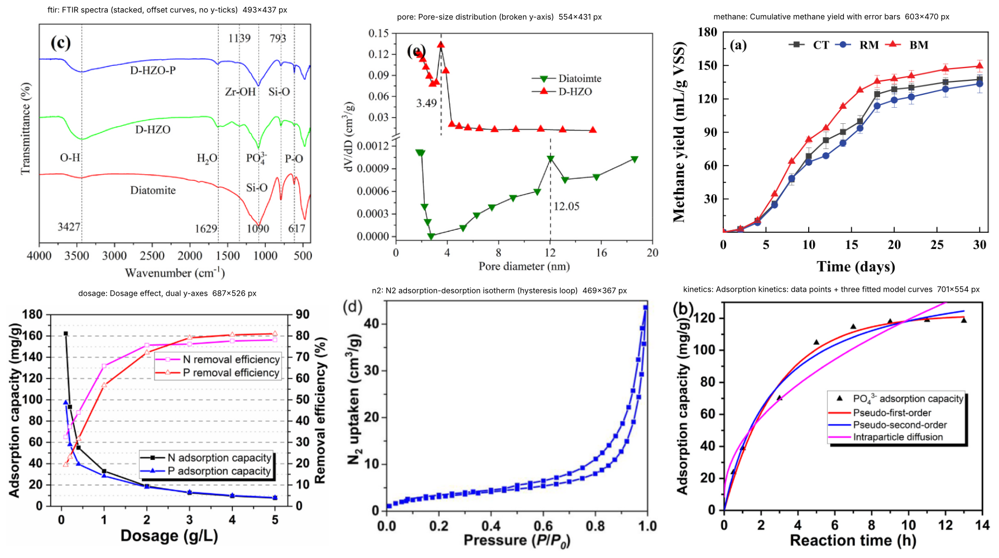

In [2]:
# dependencies (model libraries are only needed by the model cells that actually run a model)
for mod, pip in {"scipy": "scipy", "PIL": "pillow", "matplotlib": "matplotlib"}.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip])
%matplotlib inline
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import HTML, display

from chartbench import pipeline as pl, reporting as rp
from chartbench.figures import FIGURES, ORDER
from chartbench.models import (ClassicalRunner, QwenVLRunner, Qwen3VLRunner, DePlotRunner, OlmOCRRunner,
                               run_on_images, cached_count, build_prompt)

P = pl.Paths(WORK_DIR, DATA_DIR)
originals = pl.check_originals(P)
JOBS = pl.jobs(P)          # every original + every rebuilt image

def show_grid(paths, titles, ncols=3, width=18):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * 0.85 * nrows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        ax.imshow(mpimg.imread(p)); ax.set_title(t, fontsize=10)
    plt.tight_layout(); plt.show()

show_grid(originals, [f"{f}: {FIGURES[f]['title']}  {FIGURES[f]['size'][0]}x{FIGURES[f]['size'][1]} px" for f in ORDER])

## 1. v1 data from the originals (classical digitizer)
Green = found directly, blue = recovered by a local search (marker half hidden at the axis origin or cut by a
curve), orange = marker completely hidden behind another series' marker (value of the marker on top).

ftir      3 series,  660 points  
pore      2 series,   31 points  
methane   3 series,   42 points  {'local_search': 2, 'occluded': 7}
dosage    4 series,   32 points  {'local_search': 2, 'occluded': 3}
n2        2 series,   53 points  
kinetics  4 series,  368 points  {'local_search': 2}


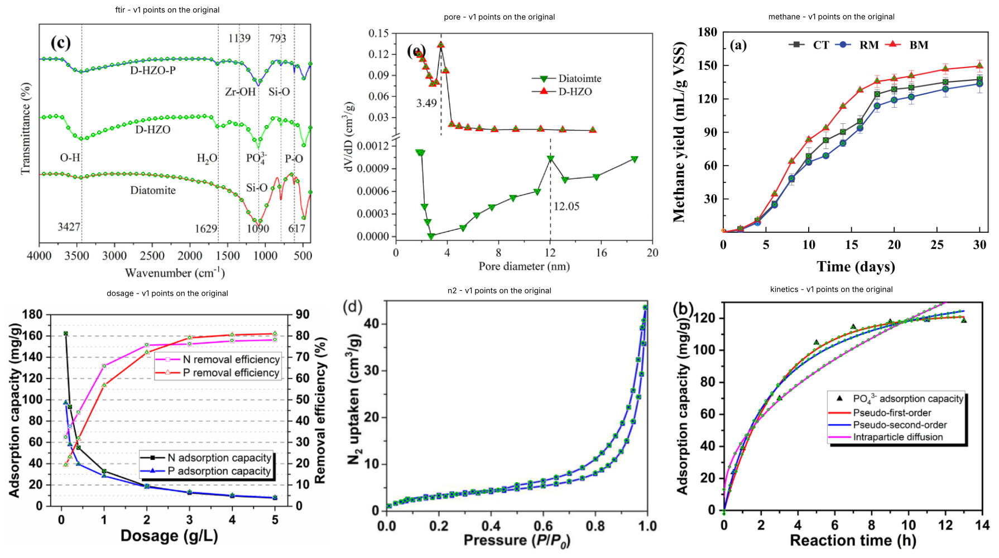

In [3]:
reference = pl.build_reference(P, force=False)
for f in ORDER:
    flags = [fl for s in reference[f]["series"].values() for fl in s.get("flags", [])]
    n = sum(len(s["x"]) for s in reference[f]["series"].values())
    extra = {k: flags.count(k) for k in sorted(set(flags)) if k != "detected"}
    print(f"{f:9s} {len(reference[f]['series'])} series, {n:4d} points  {extra if extra else ''}")
show_grid(pl.overlay_reference(P, reference), [f"{f} - v1 points on the original" for f in ORDER])

## 2. Rebuilt figures (left: original, right: rebuilt from v1)
Existing rebuilt images are kept so cached model answers always refer to the same pixels.

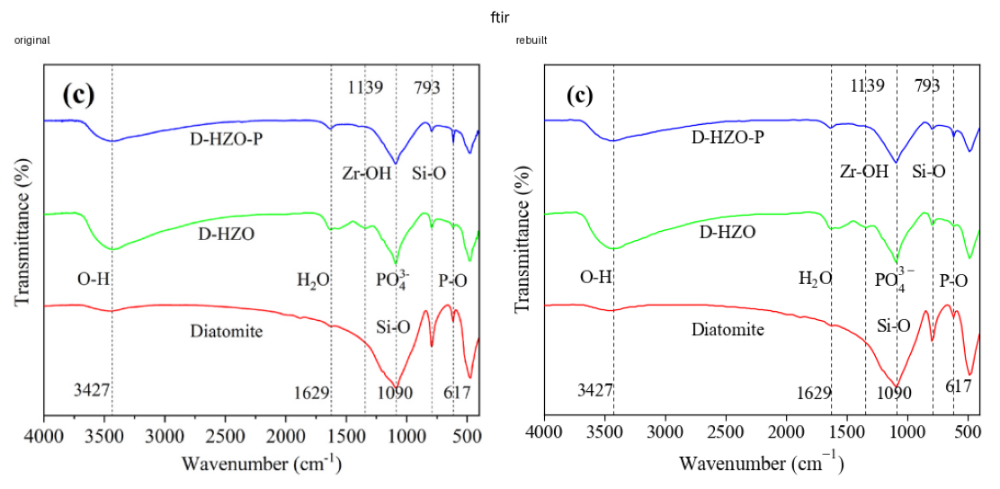

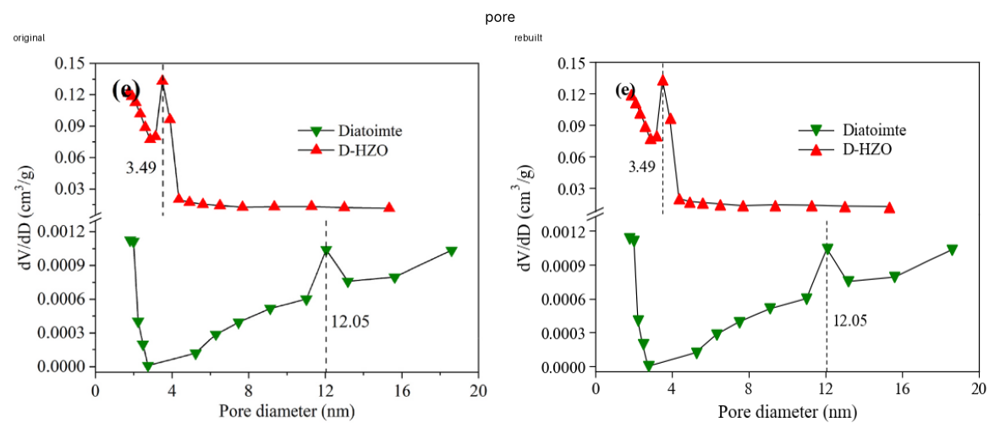

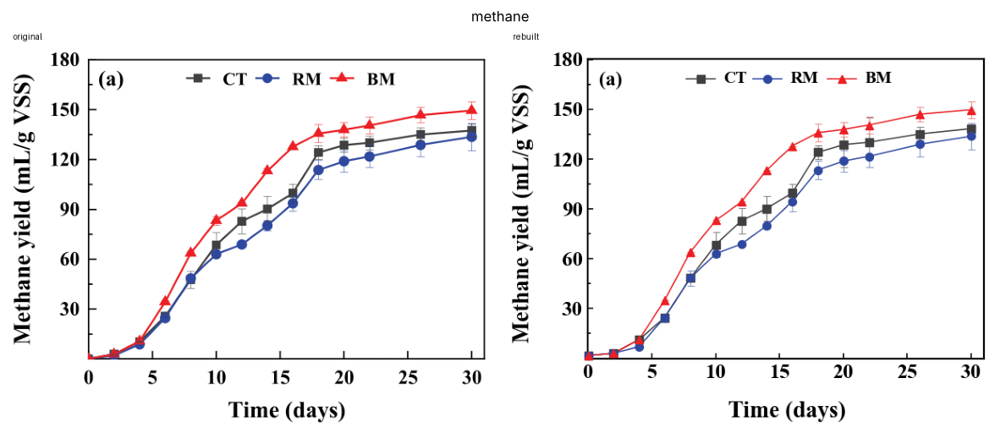

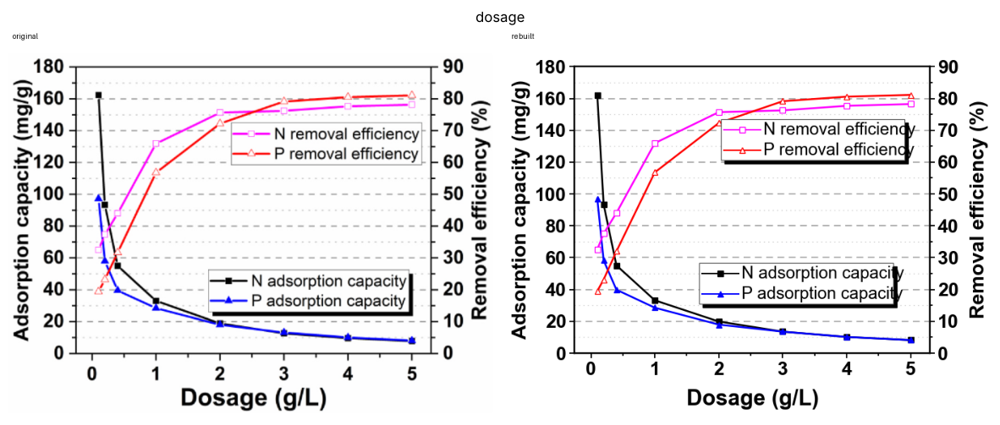

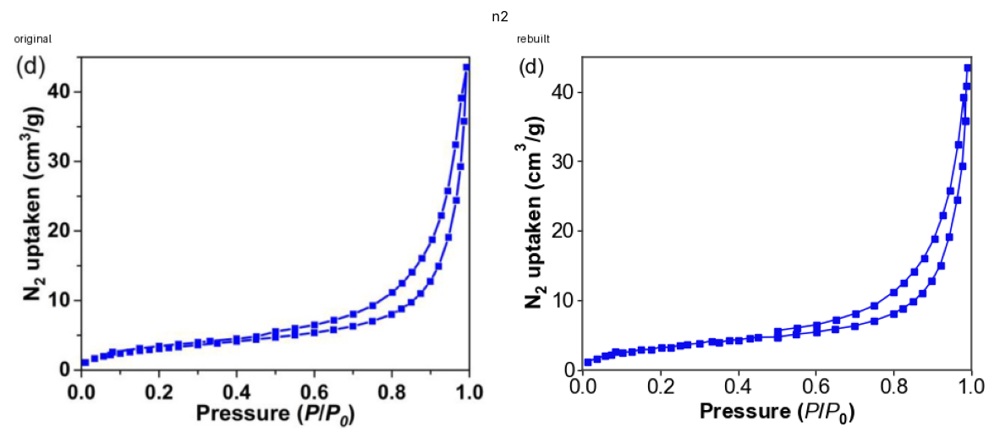

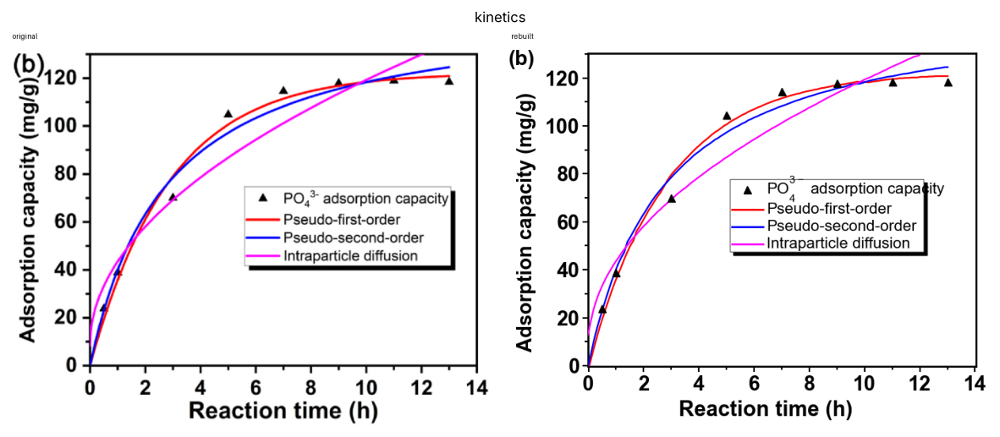

In [4]:
pl.rebuild_all(P, reference)
for f in ORDER:
    p = pl.side_by_side(P, f, P.rebuilt_img(f), f"{f}_original_vs_rebuilt.png")
    plt.figure(figsize=(15, 6.5)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.title(f); plt.show()

## 3. Models — one cell each

Each cell: runs the model only if it has no cached answers and is enabled in the settings, then shows
**one table per figure**: every truth point, the model's value at that x, the error as % of the axis
span and whether it is within ±5 %. Green rows = hit, red = miss, grey = the model returned nothing there.
The same tables are saved to `outputs/tables/<model>/<image set>.json`.

Prompt every chat-style VLM receives (example):

In [5]:
print(build_prompt("kinetics"))

def model_cell(key, make_runner):
    hf_id, enabled = config.CONFIG["models"][key]
    runner = make_runner()
    done = cached_count(runner, JOBS, P.results)
    if done < len(JOBS):
        if enabled:
            try:
                run_on_images(runner, JOBS, P.results)
            except Exception as e:
                print(f"[{runner.key}] could not run: {type(e).__name__}: {e}")
        else:
            print(f"[{runner.key}] {done}/{len(JOBS)} answers cached; not run (enable it in the settings cell: "
                  f"config.update({{'models': {{'{key}': ('{hf_id}', True)}}}}))")
    else:
        print(f"[{runner.key}] using cached answers ({done}/{len(JOBS)})")
    rp.show_model(P, runner.key)
    return runner.key

MODEL_KEYS = []

x-axis 'Reaction time (h)' (0 to 14), y-axis 'Adsorption capacity (mg/g)' (0 to 130). It shows measured data 'PO4 adsorption capacity' (black triangles) and three fitted model curves: 'Pseudo-first-order' (red), 'Pseudo-second-order' (blue) and 'Intraparticle diffusion' (magenta).

Task: extract the underlying data of this chart. List every black triangle, and give each curve sampled at x = 0, 1, 2, ..., 13 (stop where a curve leaves the plot).
Respond with ONLY a JSON object that maps each series name to a list of [x, y] number pairs, for example {"PO4 adsorption capacity": [[x1, y1], [x2, y2], ...], "Pseudo-first-order": [[x1, y1], [x2, y2], ...]}.
Use exactly these series names: ["PO4 adsorption capacity", "Pseudo-first-order", "Pseudo-second-order", "Intraparticle diffusion"]. Numbers only (no units, no strings), no explanation, no markdown.


### 3a. Classical digitizer (reference reader; uses the per-figure calibration, so it is the precision ceiling, not a fair zero-shot competitor)

In [6]:
MODEL_KEYS.append(model_cell('classical', ClassicalRunner))

[classical] using cached answers (12/12)


### 3b. Qwen2.5-VL-3B-Instruct

In [7]:
MODEL_KEYS.append(model_cell('qwen2.5-vl-3b', lambda: QwenVLRunner('Qwen/Qwen2.5-VL-3B-Instruct', key='qwen2.5-vl-3b')))

[qwen2.5-vl-3b] using cached answers (12/12)


### 3c. Qwen3-VL-4B-Instruct

In [8]:
MODEL_KEYS.append(model_cell('qwen3-vl-4b', lambda: Qwen3VLRunner('Qwen/Qwen3-VL-4B-Instruct', key='qwen3-vl-4b')))

[qwen3-vl-4b] using cached answers (12/12)


### 3d. DePlot (google/deplot) — fixed prompt, returns a table

In [9]:
MODEL_KEYS.append(model_cell('deplot', DePlotRunner))

[deplot] using cached answers (12/12)


### 3e. olmOCR-2-7B with its native page-OCR prompt (describes the figure, returns no numbers — expected)

In [10]:
MODEL_KEYS.append(model_cell('olmocr2-native', lambda: OlmOCRRunner(mode='native')))

[olmocr2-native] using cached answers (12/12)


### 3f. olmOCR-2-7B with the JSON data prompt (not run yet — disabled in the settings)

In [11]:
MODEL_KEYS.append(model_cell('olmocr2-json', lambda: OlmOCRRunner(mode='json')))

[olmocr2-json] 0/12 answers cached; not run (enable it in the settings cell: config.update({'models': {'olmocr2-json': ('allenai/olmOCR-2-7B-1025', True)}}))


### 3g. Qwen2.5-VL-7B-Instruct

In [12]:
MODEL_KEYS.append(model_cell('qwen2.5-vl-7b', lambda: QwenVLRunner('Qwen/Qwen2.5-VL-7B-Instruct', key='qwen2.5-vl-7b')))

[qwen2.5-vl-7b] using cached answers (12/12)


### 3h. Qwen3-VL-8B-Instruct (not run yet — disabled in the settings)

In [13]:
MODEL_KEYS.append(model_cell('qwen3-vl-8b', lambda: Qwen3VLRunner('Qwen/Qwen3-VL-8B-Instruct', key='qwen3-vl-8b')))

[qwen3-vl-8b] 0/12 answers cached; not run (enable it in the settings cell: config.update({'models': {'qwen3-vl-8b': ('Qwen/Qwen3-VL-8B-Instruct', True)}}))


## 4. Leaderboard (mean over all figures)
`baseline-midline` is a flat line through the middle of every y-axis — it reads nothing. A model is only
useful if it clearly beats it, especially on **hit rate**.

,label,hit_rate_rebuilt,accuracy_rebuilt,coverage_rebuilt,hit_rate_original,accuracy_original,sec_per_image_rebuilt
model,,,,,,,
classical,Classical digitizer (reference reader),99.8,99.6,100.0,100.0,100.0,0.1
qwen3-vl-4b,Qwen3-VL-4B-Instruct,34.4,78.6,100.0,35.1,80.7,16.7
qwen2.5-vl-7b,Qwen2.5-VL-7B-Instruct,26.3,70.8,99.2,23.1,72.1,26.0
qwen2.5-vl-3b,Qwen2.5-VL-3B-Instruct,20.7,69.0,90.4,22.6,77.8,11.1
deplot,DePlot (google/deplot),11.3,19.3,24.7,14.4,29.6,63.1
baseline-midline,Baseline: flat line through the middle of each axis (no model),9.9,72.7,100.0,9.9,72.7,NaN
olmocr2-native,"olmOCR-2-7B, native OCR prompt",0.0,0.0,0.0,0.0,0.0,13.0


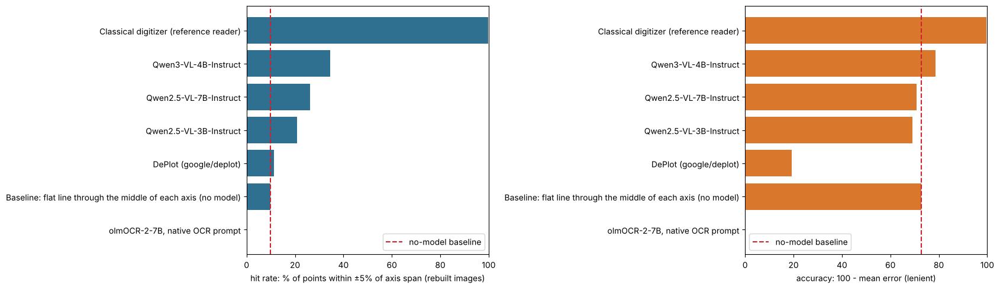

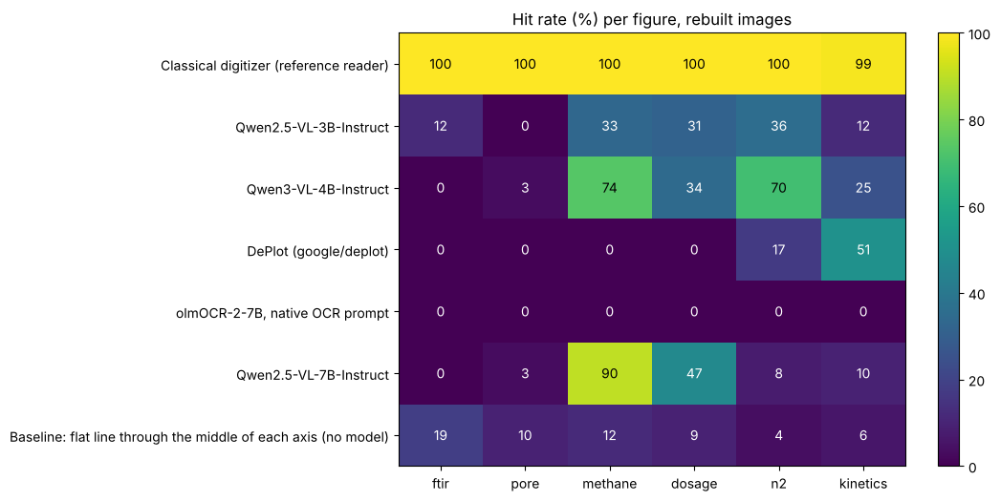

In [14]:
KEYS = [k for k in dict.fromkeys(MODEL_KEYS) if (P.results / k).exists()]
lb = rp.leaderboard(P, KEYS)
cols = [c for c in ["label", "hit_rate_rebuilt", "accuracy_rebuilt", "coverage_rebuilt",
                    "hit_rate_original", "accuracy_original", "sec_per_image_rebuilt"] if c in lb]
display(lb[cols].round(1))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
order = lb.index[::-1]
base = lb.loc["baseline-midline"]
axes[0].barh([rp.label(k) for k in order], lb.loc[order, "hit_rate_rebuilt"], color="#2f6f8f")
axes[0].axvline(base["hit_rate_rebuilt"], color="#cf222e", ls="--", label="no-model baseline")
axes[0].set_xlabel("hit rate: % of points within ±5% of axis span (rebuilt images)"); axes[0].set_xlim(0, 100); axes[0].legend()
axes[1].barh([rp.label(k) for k in order], lb.loc[order, "accuracy_rebuilt"], color="#d9782d")
axes[1].axvline(base["accuracy_rebuilt"], color="#cf222e", ls="--", label="no-model baseline")
axes[1].set_xlabel("accuracy: 100 - mean error (lenient)"); axes[1].set_xlim(0, 100); axes[1].legend()
plt.tight_layout(); plt.show()

hm = rp.per_figure_matrix(P, KEYS, "hit_rate")
fig, ax = plt.subplots(figsize=(11, 0.55 * len(hm) + 1.5))
im = ax.imshow(hm.values, cmap="viridis", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER); ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if v == v:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v < 60 else "black")
ax.set_title("Hit rate (%) per figure, rebuilt images"); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 5. Why the models fall short — computed evidence

**What the models return, plotted against the truth** (one series per figure, rebuilt images):

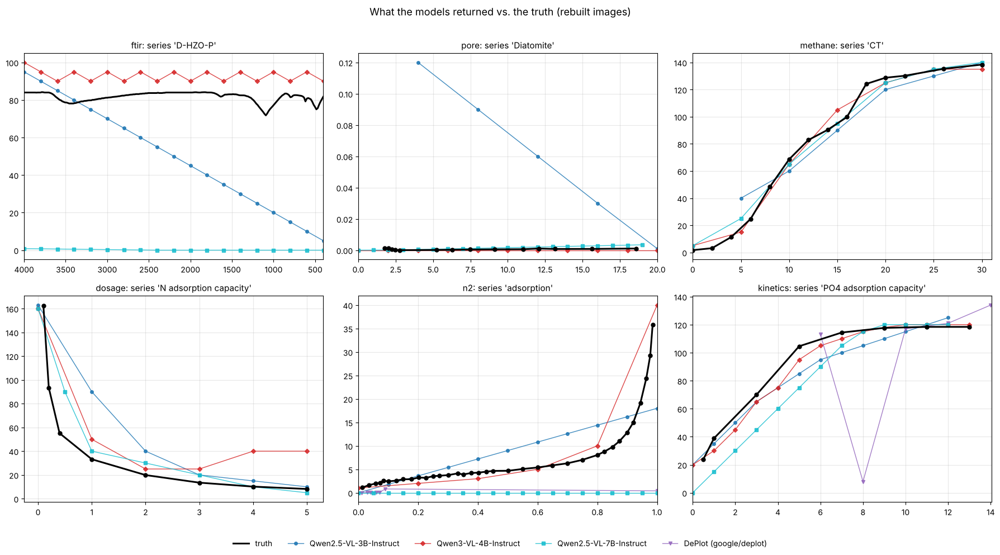

In [15]:
fig = rp.plot_extractions(P, KEYS, "rebuilt"); plt.show()

In [16]:
print("Signs of a template answer instead of a reading (rebuilt images):")
dg = rp.diagnostics(P, KEYS); display(dg.round(1))
print("How much the model actually sees: visual tokens per image at the configured input size")
display(rp.visual_token_table())

Signs of a template answer instead of a reading (rebuilt images):


,label,points returned / truth points,series with constant y (%),series with perfectly even y-steps (%),marker series answered on an invented even x-grid (%),x-placement error of markers (% of x-axis),figures with identical answer for original & rebuilt,visual tokens per image (min-max),note
model,,,,,,,,,
qwen2.5-vl-3b,Qwen2.5-VL-3B-Instruct,183 / 316,0.0,38.9,100.0,3.5,0.0,221-500 (computed),NaN
qwen3-vl-4b,Qwen3-VL-4B-Instruct,192 / 316,11.1,0.0,100.0,3.2,0.0,165-374 (computed),NaN
deplot,DePlot (google/deplot),106 / 316,12.5,0.0,50.0,15.8,0.0,n/a (Pix2Struct patches),NaN
olmocr2-native,"olmOCR-2-7B, native OCR prompt",0 / 316,NaN,NaN,NaN,NaN,NaN,NaN,returned no data points at all
qwen2.5-vl-7b,Qwen2.5-VL-7B-Instruct,240 / 316,11.1,22.2,66.7,1.7,1.0,221-500 (computed),NaN


How much the model actually sees: visual tokens per image at the configured input size


,image fed (px),Qwen2.5-VL tokens (28 px each),Qwen3-VL tokens (32 px each),olmOCR tokens (1288 px input),typical marker size (px),marker area / token area (Qwen2.5)
figure,,,,,,
ftir,493x437,288,210,1221,line plot,—
pore,554x431,300,221,1240,9.0,0.1
methane,603x470,374,285,1240,9.8,0.12
dosage,687x526,475,336,1240,7.9,0.08
n2,469x367,221,165,1240,5.5,0.04
kinetics,701x554,500,374,1240,10.0,0.13


**What the evidence says**

1. **They answer on an invented, evenly spaced x-grid instead of at the markers.** For marker series the truth
   sits at uneven x (dosage: 0.1, 0.2, 0.4, 1, 2, 3, 4, 5 g/L; kinetics: 0.5, 1, 3, 5, … h), but the VLMs return
   x = 0, 1, 2, … or 0, 5, 10, … (see the *invented even x-grid* column). They describe the *trend* of a curve
   rather than locating each marker, so steep regions (dosage 0.1–1 g/L, the N₂ jump near P/P₀ = 1, the
   kinetic rise) are badly missed.
2. **Several answers are templates, not readings:** constant values (FTIR = 100 for every point, N₂
   desorption = 0), perfectly even steps (95, 90, 85, … ; 0.0001, 0.0002, …), and the 7B returning the
   *identical* answer for the original and the rebuilt image. That is the model filling the requested JSON
   shape, not reading pixels.
3. **The images are small for these models.** At native size a figure becomes only ~165–500 visual tokens; one
   Qwen2.5-VL token covers 28×28 px, a marker is 5–10 px, i.e. **4–13 % of a single token**. Dense markers,
   thin offset spectra and broken/dual axes are below what the model resolves. (Setting `upscale` gives
   it 4× the tokens at 2×.)
4. **"Trained on similar tasks" ≠ this task.** Their chart training (ChartQA, PlotQA, DePlot's synthetic
   charts) is mostly bar/line/pie charts from news and statistics sites with few series, and is scored on
   *single* values with ±5 % tolerance — often values printed on the chart. Here the models must output
   20–75 coordinates per figure from scientific plots with no printed values, dual and broken axes, offset
   spectra without y-ticks and overlapping markers. Methane (simple axes, well-separated series) is where
   they do best (Qwen2.5-VL-7B 90 % hit rate); FTIR and the broken-axis pore plot are near 0.
5. **Model-specific:** **DePlot** can't be told the series names or axes; it emits axis titles as table
   rows and returns 2 of 4 series for dosage, so most points are missing. **olmOCR (native prompt)** is a
   page-transcription model: it correctly transcribed every label in the FTIR figure but, by design,
   describes figures instead of reading values.
6. **Long JSON + greedy decoding** encourages repetitive patterns (the 7B's rows of zeros). Asking for one
   series at a time (`prompt.mode = "per_series"`) shortens each answer.

**What to try next (all switchable in the settings cell, each gets its own result folder):** upscale 2–3×;
per-series prompting; give the x positions and ask only for y (turns it into the ChartQA-style task the
models were trained on); Qwen3-VL-8B; fine-tune on synthetic charts in this style (exact ground truth for free).


## 6. Presentation figures — exact ground truth vs. what each model extracted

One slide-ready figure per model and per plot (`outputs/presentation/<model>/<figure>.png`):
**left** = the rebuilt figure (exact ground truth, the image the model read);
**right** = only the values the model extracted from it, re-plotted with the same axes, style and legend.
Any difference between the two is an extraction error. Values the model put outside the axis ranges
cannot be drawn; their count is in the panel title. Only rebuilt images are used here because only they
have exact ground truth.

Below the per-model figures: one grouped bar chart of the error of every model on every plot
(`outputs/presentation/error_by_model_and_plot.png`).

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


... (6 outputs left out)

findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


findfont: Failed to find font weight bold for cmex10, now using 400.


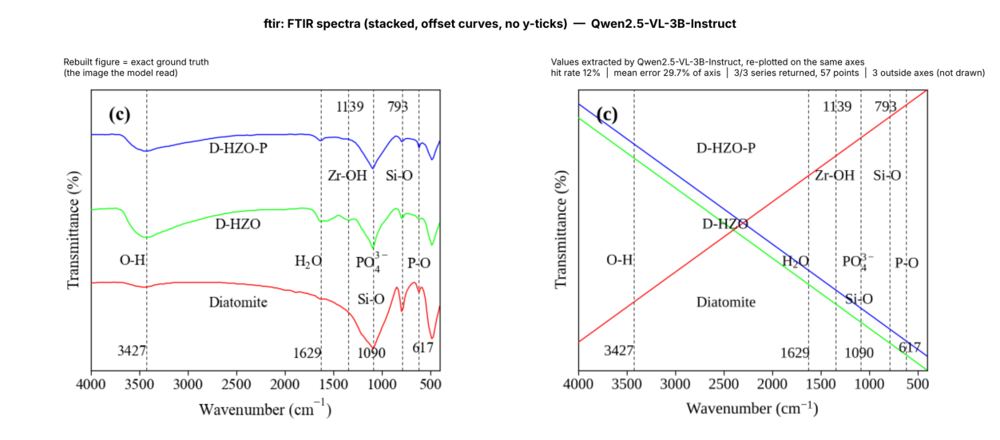

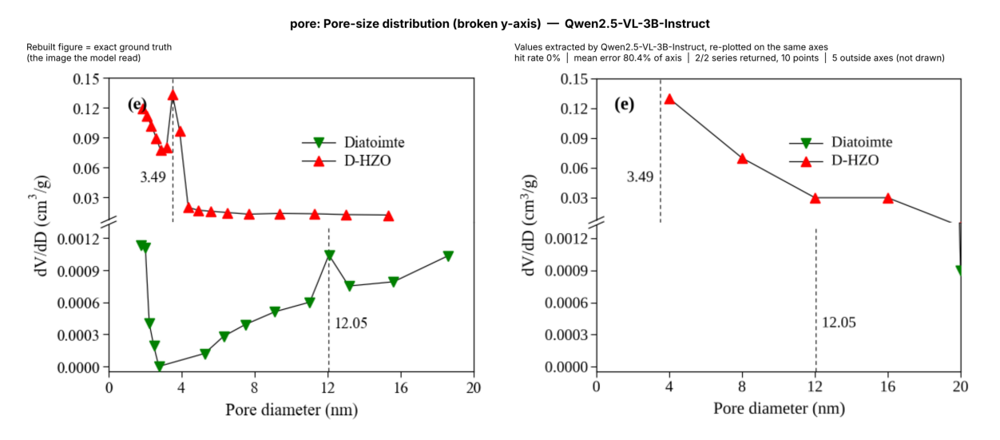

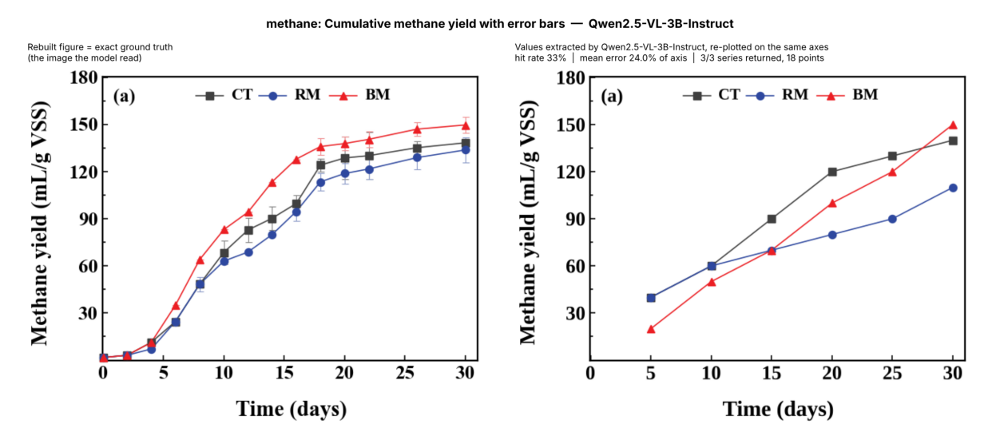

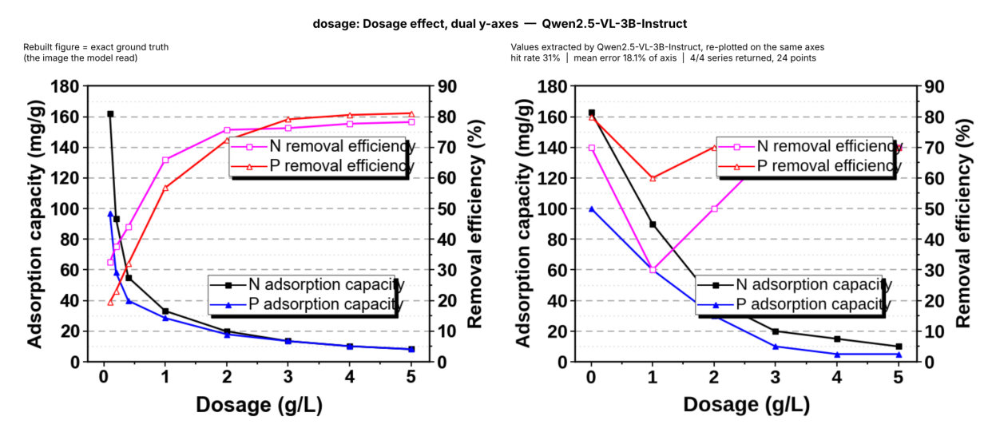

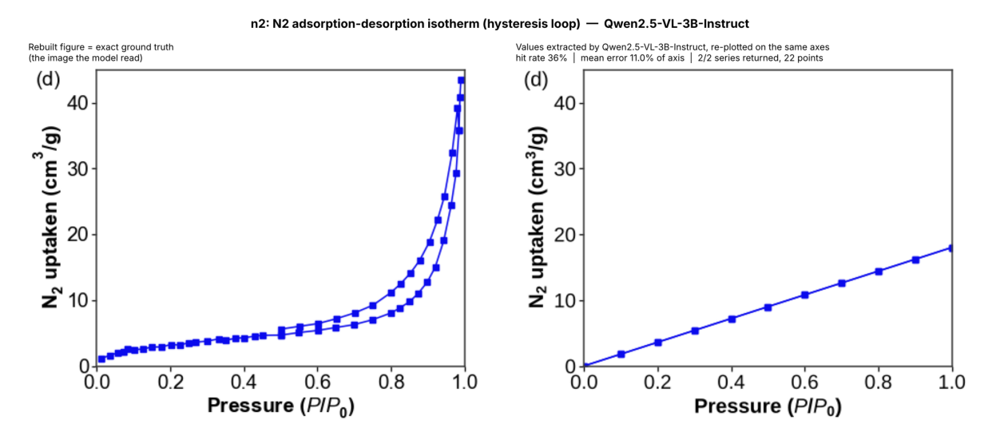

...

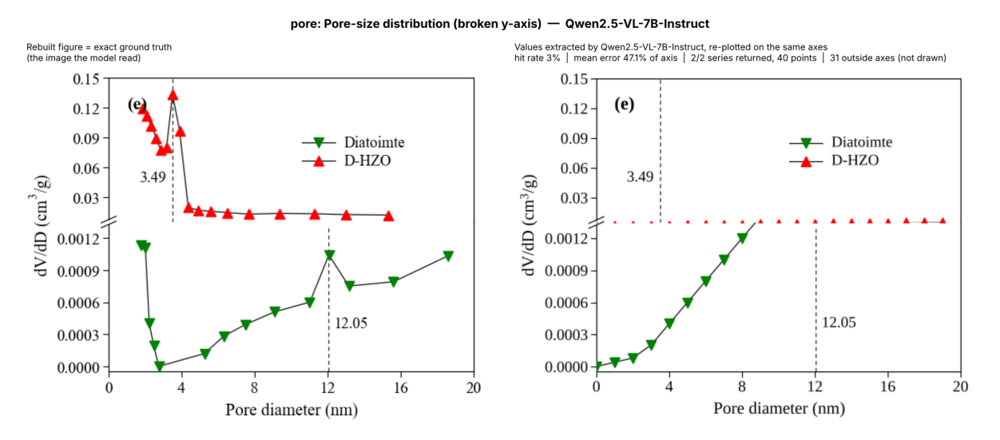

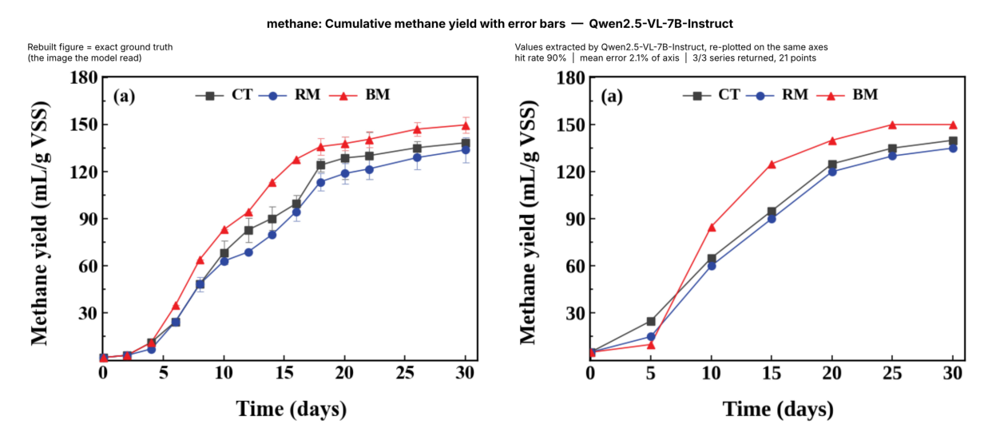

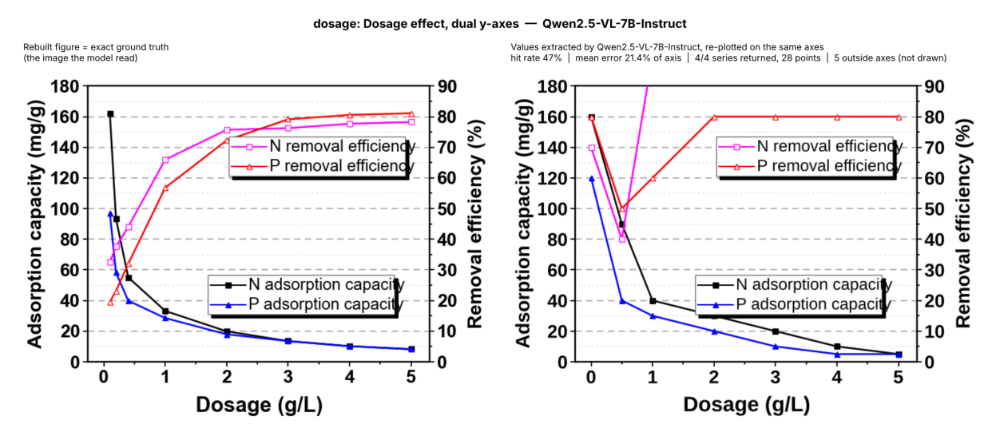

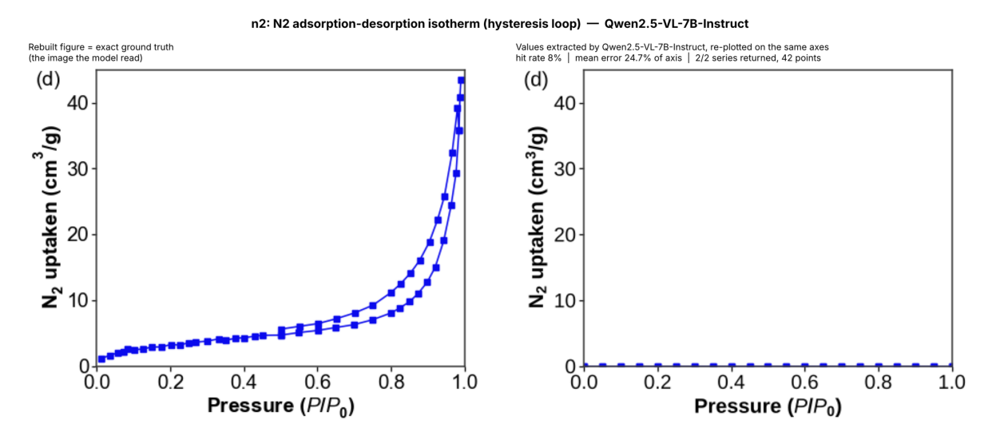

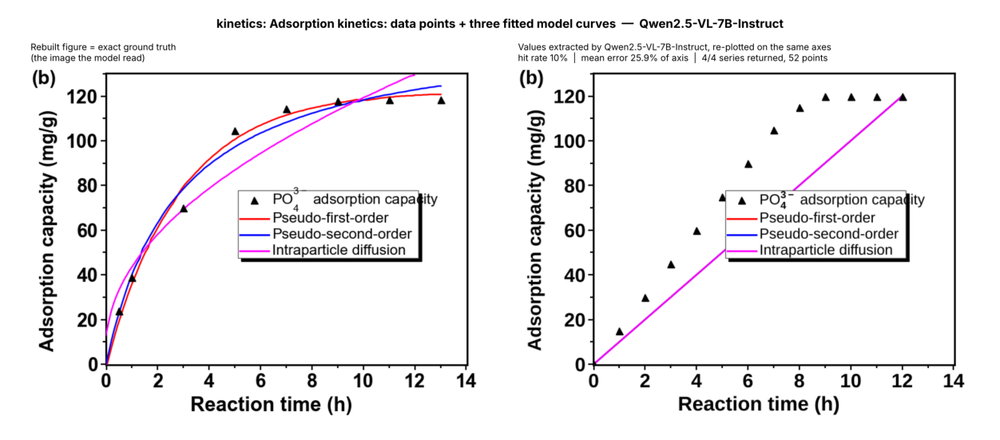

In [17]:
SHOW_MODELS = [k for k in KEYS if k != "classical"]     # e.g. ["qwen3-vl-4b"]
paths = rp.presentation_all(P, KEYS)
for key in SHOW_MODELS:
    display(HTML(f"<h3>{rp.label(key)}</h3>"))
    for f in ORDER:
        p = paths.get((key, f))
        if p:
            plt.figure(figsize=(16, 6.9)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()

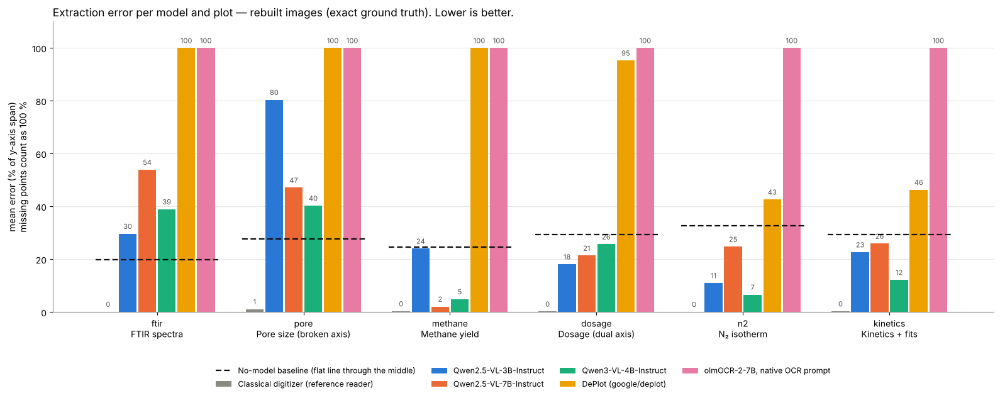

saved: /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/presentation/error_by_model_and_plot.png


In [18]:
fig, p = rp.error_bar_chart(P, KEYS)
plt.show()
print("saved:", p)

## 7. Save everything (JSON tables + standalone HTML report)

In [19]:
p_json = rp.save_all(P, KEYS)
p_html = rp.write_report(P, KEYS)
print("tables (one file per model and image set):", P.work / "outputs" / "tables")
print("all tables in one file:", p_json)
print("standalone report      :", p_html)
print("leaderboard / diagnostics CSV:", P.work / "outputs" / "leaderboard.csv", P.work / "outputs" / "diagnostics.csv")

tables (one file per model and image set): /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/tables
all tables in one file: /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/tables/all_models.json
standalone report      : /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/report.html
leaderboard / diagnostics CSV: /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/leaderboard.csv /root/work/t4/step04b_plot_extraction/02_real_plots_multimodel/outputs/diagnostics.csv


## Raw model output (debugging a single answer)

In [20]:
MODEL, IMAGE_SET, FIG = "qwen3-vl-4b", "rebuilt", "dosage"
a = pl.load_answer(P, MODEL, IMAGE_SET, FIG)
if a:
    print(json.dumps(a.get("run_config", "run_config not recorded (run made before it was added; defaults applied)"), indent=1)[:1500])
    print("\n--- raw answer ---\n", a["raw"][:3000])
else:
    print("no answer cached for that combination")

"run_config not recorded (run made before it was added; defaults applied)"

--- raw answer ---
 {
  "N adsorption capacity": [
    [0, 160],
    [1, 50],
    [2, 25],
    [3, 25],
    [4, 40],
    [5, 40]
  ],
  "P adsorption capacity": [
    [0, 100],
    [1, 30],
    [2, 20],
    [3, 15],
    [4, 10],
    [5, 10]
  ],
  "N removal efficiency": [
    [0, 60],
    [1, 80],
    [2, 80],
    [3, 80],
    [4, 80],
    [5, 80]
  ],
  "P removal efficiency": [
    [0, 40],
    [1, 120],
    [2, 150],
    [3, 160],
    [4, 165],
    [5, 165]
  ]
}


## 8. Extended set — every figure of `data/` and `data/test_data/` with a profile

Ground truth comes from `main_Hardcoded_ground_truth_generation.ipynb` (stage 3): `outputs/ground_truth/<figure>.json`.
Multi-panel and inset figures keep their panels apart, so the prompt describes every panel and asks for
`{panel id: {series name: [[x, y], ...]}}`; answers are scored per panel against that panel's own y-axis span
(hit = within 5 %). Figures flagged in the QA are scored too but listed separately below.

Answers are cached in `outputs/model_results/<model>/<image set>_extended/<figure>.json` (prompt + raw text + parsed).

In [ ]:
from chartbench import extended as X
EXT = X.ids()
missing_gt = [f for f in EXT if not (P.ground_truth / f'{f}.json').exists()]
if missing_gt:
    print('ground truth missing - run main_Hardcoded_ground_truth_generation.ipynb (stage 3) first:', missing_gt)
print(len(EXT), 'extended figures')
print(X.build_prompt('nutrient_energy'))   # example: a main plot with an inset bar chart


### 8a. Qwen3-VL-4B on the extended set (rebuilt images = exact ground truth)

In [ ]:
EXT_SET = 'rebuilt'      # 'rebuilt' (exact ground truth) or 'original'
if config.CONFIG['models']['qwen3-vl-4b'][1]:
    X.run_model(Qwen3VLRunner('Qwen/Qwen3-VL-4B-Instruct', key='qwen3-vl-4b'), P, EXT_SET)


### 8b. Qwen2.5-VL-7B on the extended set

In [ ]:
if config.CONFIG['models']['qwen2.5-vl-7b'][1]:
    X.run_model(QwenVLRunner('Qwen/Qwen2.5-VL-7B-Instruct', key='qwen2.5-vl-7b'), P, EXT_SET)


### 8c. Leaderboard on the extended set

In [ ]:
import json
ext_keys = [k for k in dict.fromkeys(MODEL_KEYS + ['qwen3-vl-4b', 'qwen2.5-vl-7b']) if (P.results / k / f'{EXT_SET}_extended').exists()]
display(X.leaderboard(P, ext_keys, EXT_SET))
flag = {f: json.loads((P.ground_truth / f'{f}.json').read_text()).get('qa', {}).get('flagged') for f in EXT
        if (P.ground_truth / f'{f}.json').exists()}
print('figures whose rebuild was flagged in the QA:', [f for f, v in flag.items() if v])
